<a href="https://colab.research.google.com/github/GAEL328530/Lab-pdi-PR-CTICAS/blob/main/Practica_6_PDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 6.- Operaciones aritméticas y lógicas

**Universidad Autónoma de Nuevo León – Facultad de Ingeniería Mecánica y Eléctrica**
Semestre: Enero-Junio 2026

**Integrantes:**

| Nombre completo | Matrícula | Brigada | Día y hora |
|---|---|---|---|
|Alexa Rodríguez Méndez |2133921 |309 |n5 |
|Gael Alejandro Reyes Zaragoza |2178099 |309 |n5 |
|René Alejandro Rodríguez Castañeda |2019068 |309 |n5 |

**Objetivo:** realizar modificaciones a imágenes médicas en el dominio del espacio mediante operaciones aritméticas (suma, resta y multiplicación) y ecualización de histograma, además de una demostración de operaciones lógicas.

**Contenido**
- **Parte I.** Operaciones aritméticas: suma, resta, multiplicación por un factor y multiplicación elemento por elemento (con dos radiografías).
- **Parte II.** Ecualización de histograma (con una radiografía de bajo contraste) y complemento de operaciones lógicas.

**Librerías:** OpenCV, NumPy y Matplotlib.

## 0. Preparación

Se importan las librerías, se descargan las radiografías que se usan en la práctica y se define la función `mostrar()`, que despliega varias imágenes en escala de grises en una cuadrícula.

In [ ]:
import os
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100

BASE = "https://raw.githubusercontent.com/asalmada/x-ray-images-enhancement/master/images/"
ARCHIVOS = {
    "fibroma1.jpg": "nonossifying_fibroma1.jpg",   # Parte I - imagen 1
    "fibroma2.jpg": "nonossifying_fibroma2.jpg",   # Parte I - imagen 2
    "torax_bajo_contraste.jpg": "001.jpg",         # Parte II
}

os.makedirs("imagenes", exist_ok=True)
for local, remoto in ARCHIVOS.items():
    ruta = os.path.join("imagenes", local)
    if not os.path.exists(ruta):
        urllib.request.urlretrieve(BASE + remoto, ruta)
    print("Listo:", ruta)

def mostrar(imagenes, titulos, cols=None, figsize=None, vmin=0, vmax=255):
    """Muestra una lista de imágenes en escala de grises en una cuadrícula."""
    n = len(imagenes)
    cols = cols or n
    filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols, figsize=figsize or (4.2 * cols, 4.4 * filas))
    axs = np.array(axs).reshape(-1)
    for ax, im, t in zip(axs, imagenes, titulos):
        ax.imshow(im, cmap="gray", vmin=vmin, vmax=vmax)
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    for ax in axs[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

Listo: imagenes/fibroma1.jpg
Listo: imagenes/fibroma2.jpg
Listo: imagenes/torax_bajo_contraste.jpg


# Parte I.- Operaciones aritméticas

## Ejercicio 1: Suma de imágenes

1. Se cargan las dos imágenes en escala de grises. Si tienen distinto tamaño, la segunda se redimensiona a la resolución de la primera con `cv2.resize`.
2. Suma ponderada `g = α·f₁ + β·f₂` con `cv2.addWeighted`, usando tres combinaciones de pesos.
3. Suma promedio `g = (f₁ + f₂) / 2`, calculada en `float32` para no desbordar `uint8`.
4. Se muestran los resultados junto a las imágenes originales.

Tamaño original imagen 1 (alto, ancho): (336, 383)
Tamaño original imagen 2 (alto, ancho): (374, 336)
Tamaño imagen 2 tras ajuste:             (336, 383)


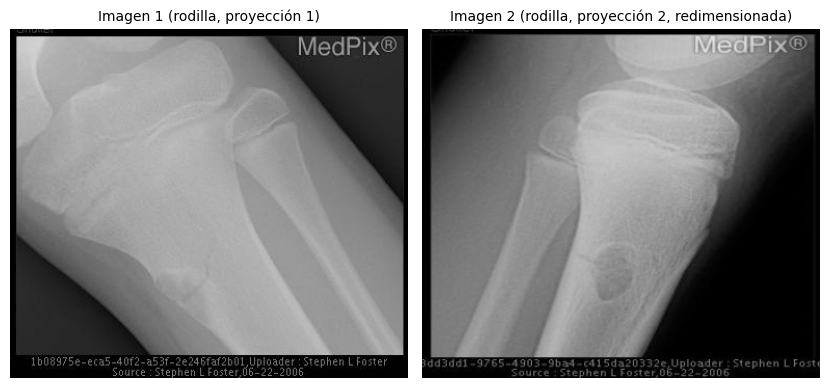

In [ ]:
# 1) Cargar en escala de grises y ajustar a la misma resolución
img1 = cv2.imread("imagenes/fibroma1.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("imagenes/fibroma2.jpg", cv2.IMREAD_GRAYSCALE)
print("Tamaño original imagen 1 (alto, ancho):", img1.shape)
print("Tamaño original imagen 2 (alto, ancho):", img2.shape)

img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]), interpolation=cv2.INTER_LINEAR)
print("Tamaño imagen 2 tras ajuste:            ", img2.shape)

mostrar([img1, img2], ["Imagen 1 (rodilla, proyección 1)", "Imagen 2 (rodilla, proyección 2, redimensionada)"])

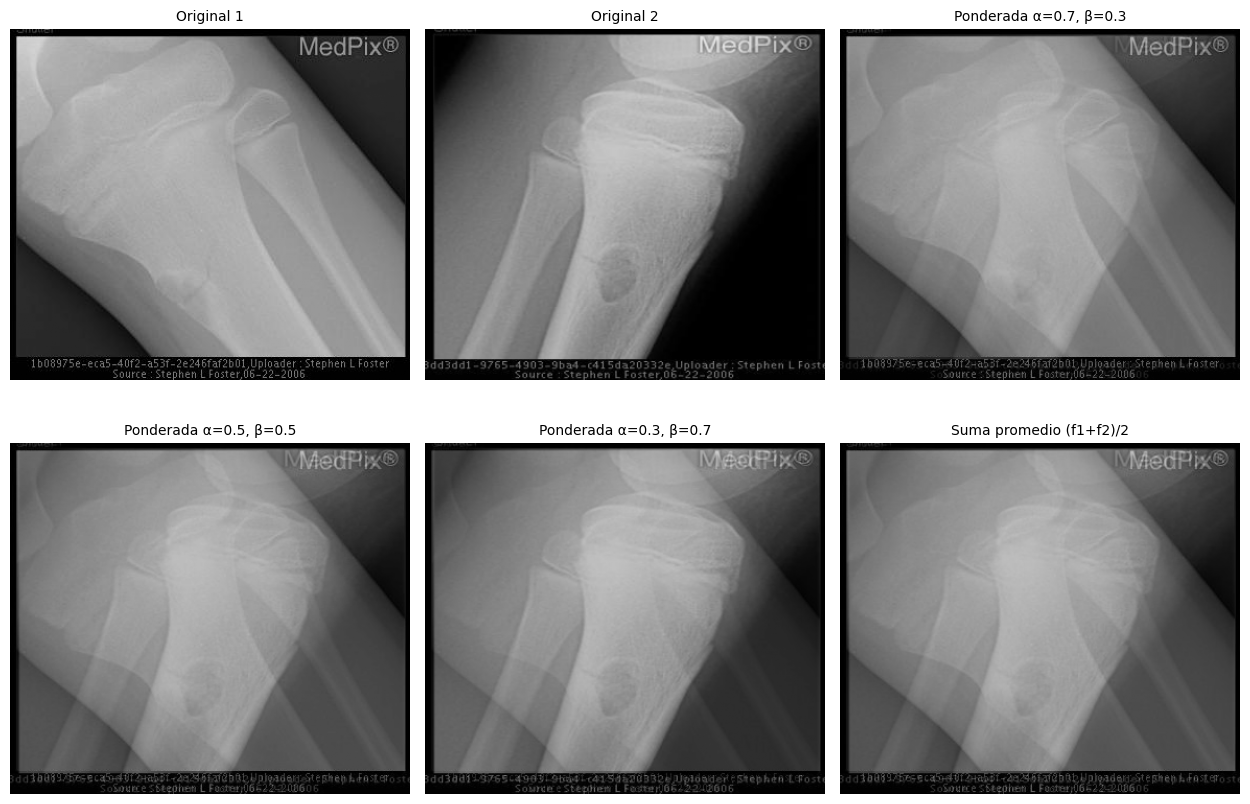

Ponderada α=0.7, β=0.3: media=113.9  desv.est.=52.4
Ponderada α=0.5, β=0.5: media=108.9  desv.est.=51.4
Ponderada α=0.3, β=0.7: media=104.0  desv.est.=54.9
Promedio: media=108.7  desv.est.=51.4
Original 1: media=121.4  Original 2: media=96.5


In [ ]:
# 2) Suma ponderada con diferentes pesos: g = alfa*f1 + beta*f2
pesos = [(0.7, 0.3), (0.5, 0.5), (0.3, 0.7)]
ponderadas = [cv2.addWeighted(img1, a, img2, b, 0) for a, b in pesos]

# 3) Suma promedio (en float para evitar desbordamiento de uint8)
promedio = ((img1.astype(np.float32) + img2.astype(np.float32)) / 2).astype(np.uint8)

# 4) Mostrar resultados con las imágenes originales
mostrar(
    [img1, img2] + ponderadas + [promedio],
    ["Original 1", "Original 2"]
    + [f"Ponderada α={a}, β={b}" for a, b in pesos]
    + ["Suma promedio (f1+f2)/2"],
    cols=3,
)

for (a, b), r in zip(pesos, ponderadas):
    print(f"Ponderada α={a}, β={b}: media={r.mean():.1f}  desv.est.={r.std():.1f}")
print(f"Promedio: media={promedio.mean():.1f}  desv.est.={promedio.std():.1f}")
print(f"Original 1: media={img1.mean():.1f}  Original 2: media={img2.mean():.1f}")

## Ejercicio 2: Resta de imágenes

Se restan las dos imágenes de distintas formas para comparar cómo se comporta cada una con los valores negativos:
- Operador de NumPy sobre `uint8`: el resultado negativo "da la vuelta" (wrap-around).
- `cv2.subtract`: satura los valores negativos en 0 (se hace en ambos sentidos).
- `cv2.absdiff`: calcula `|f₁ − f₂|`, sin valores negativos.

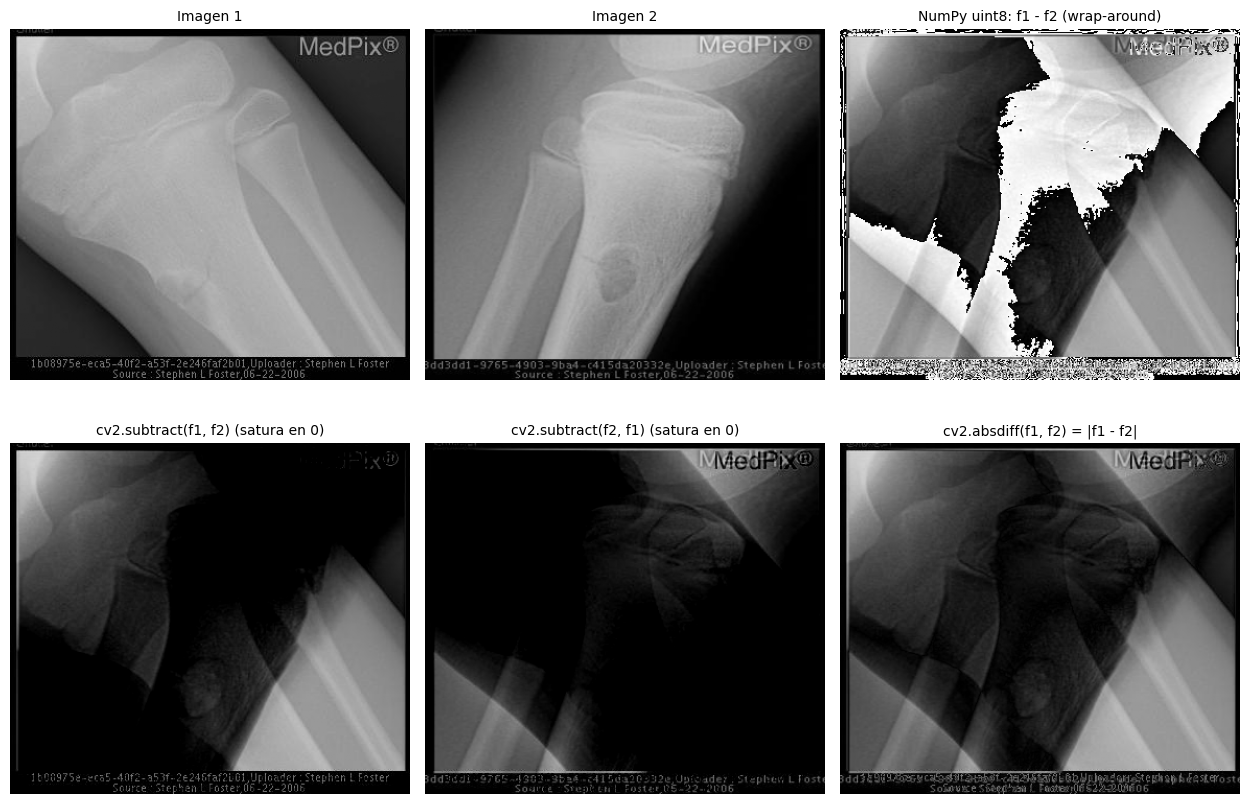

Píxeles con diferencia negativa (f1 < f2): 40.5 %
Diferencia absoluta: media=61.2, máx=219


In [ ]:
# Resta con NumPy (uint8): desbordamiento circular
resta_numpy = img1 - img2

# Resta con saturación: lo negativo se trunca a 0
resta_sat_12 = cv2.subtract(img1, img2)   # max(f1 - f2, 0)
resta_sat_21 = cv2.subtract(img2, img1)   # max(f2 - f1, 0)

# Diferencia absoluta: |f1 - f2|
dif_abs = cv2.absdiff(img1, img2)

mostrar(
    [img1, img2, resta_numpy, resta_sat_12, resta_sat_21, dif_abs],
    ["Imagen 1", "Imagen 2",
     "NumPy uint8: f1 - f2 (wrap-around)",
     "cv2.subtract(f1, f2) (satura en 0)",
     "cv2.subtract(f2, f1) (satura en 0)",
     "cv2.absdiff(f1, f2) = |f1 - f2|"],
    cols=3,
)

# Cuántos píxeles son negativos en la resta real (y por lo tanto afectados)
resta_real = img1.astype(np.int16) - img2.astype(np.int16)
neg = (resta_real < 0).mean() * 100
print(f"Píxeles con diferencia negativa (f1 < f2): {neg:.1f} %")
print(f"Diferencia absoluta: media={dif_abs.mean():.1f}, máx={dif_abs.max()}")

## Ejercicio 3: Multiplicación por un factor

Se multiplica cada imagen por una constante `g = k·f(x,y)` para cambiar su brillo, con `cv2.convertScaleAbs(img, alpha=k)`, que satura el resultado a [0, 255]. Se prueban tres factores por imagen (0.5, 1.5 y 2.5) y se imprime la media y el porcentaje de píxeles saturados en 255.

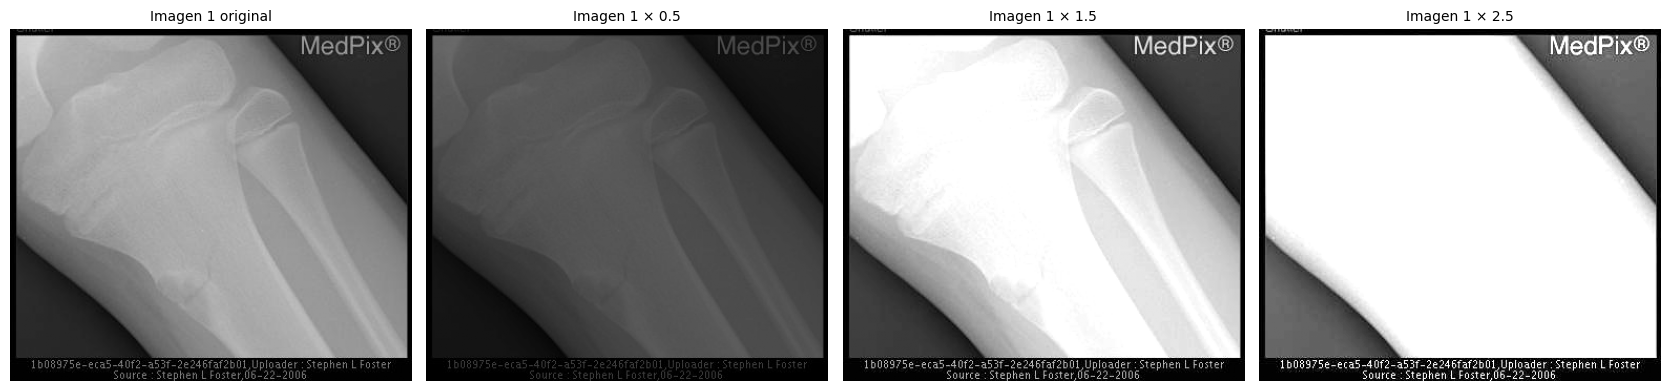

--- Imagen 1 ---
Original: media=121.4, saturados(255)=0.00 %
k=0.5: media=60.7, saturados(255)=0.00 %
k=1.5: media=179.6, saturados(255)=27.26 %
k=2.5: media=204.4, saturados(255)=70.64 %


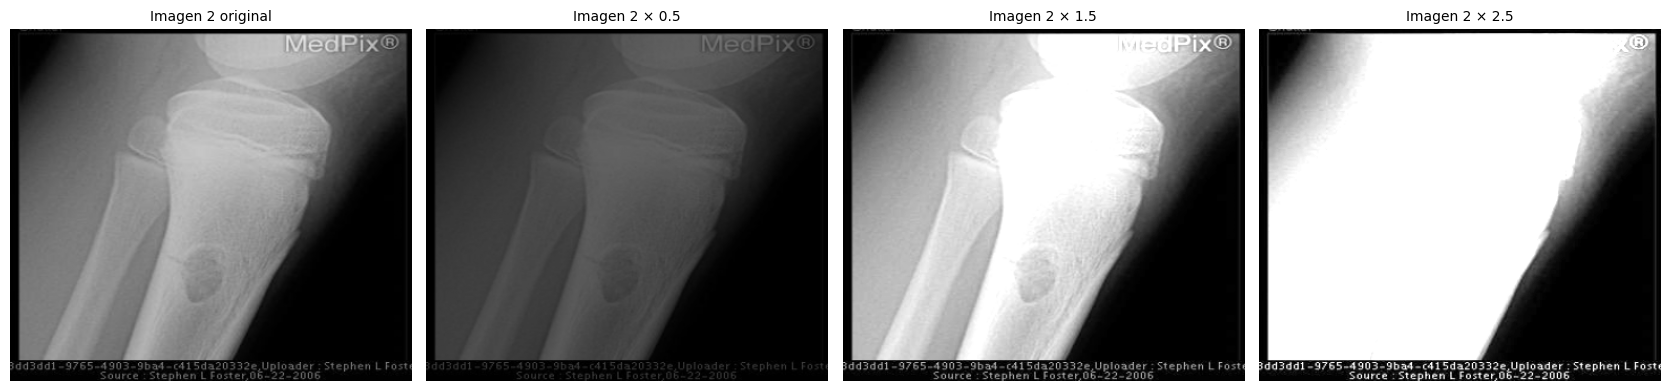

--- Imagen 2 ---
Original: media=96.5, saturados(255)=0.00 %
k=0.5: media=48.2, saturados(255)=0.00 %
k=1.5: media=141.7, saturados(255)=15.40 %
k=2.5: media=175.0, saturados(255)=57.64 %


In [ ]:
factores = [0.5, 1.5, 2.5]

for nombre, im in [("Imagen 1", img1), ("Imagen 2", img2)]:
    resultados = [cv2.convertScaleAbs(im, alpha=k) for k in factores]
    mostrar(
        [im] + resultados,
        [f"{nombre} original"] + [f"{nombre} × {k}" for k in factores],
        cols=4,
    )
    print(f"--- {nombre} ---")
    print(f"Original: media={im.mean():.1f}, saturados(255)={(im == 255).mean()*100:.2f} %")
    for k, r in zip(factores, resultados):
        print(f"k={k}: media={r.mean():.1f}, saturados(255)={(r == 255).mean()*100:.2f} %")

## Ejercicio 4: Multiplicación elemento por elemento

Se multiplican las dos imágenes píxel a píxel, `g(x,y) = f₁(x,y)·f₂(x,y)`:
- Primero con `cv2.multiply` sobre `uint8` (el resultado satura casi por completo).
- Después normalizando a [0, 1], multiplicando y reescalando a [0, 255].

Además, se muestra un ejemplo de aplicación: multiplicar la imagen por una máscara binaria (región de interés).

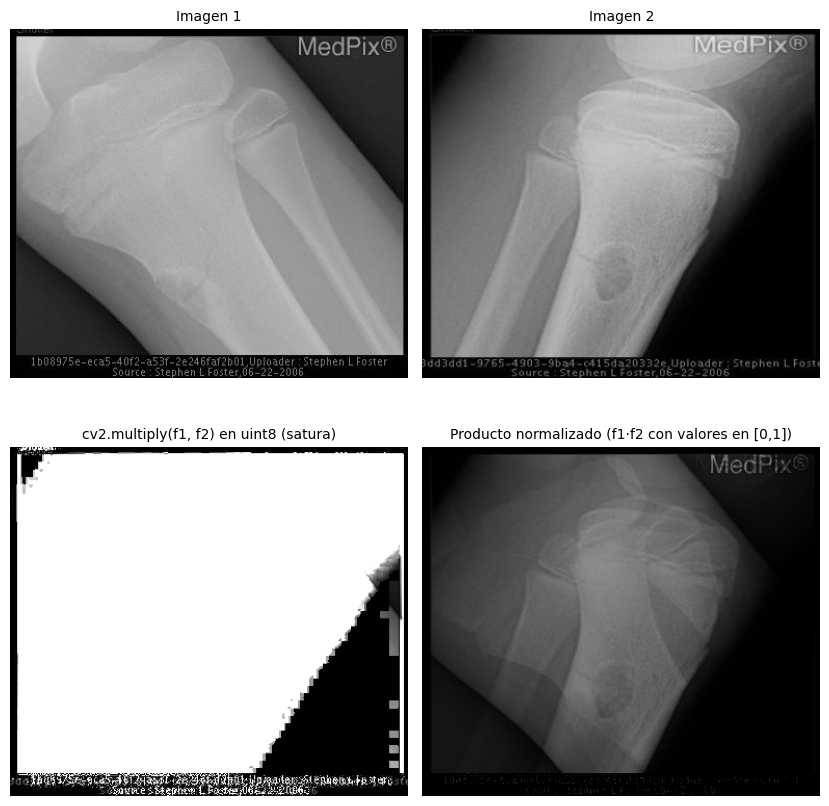

Producto con saturación : media=201.6, píxeles en 255 = 77.5 %
Producto normalizado    : media=50.0, píxeles en 255 = 0.00 %


In [ ]:
# Multiplicación directa en uint8 (satura)
prod_sat = cv2.multiply(img1, img2)

# Multiplicación normalizada a [0,1]
f1 = img1.astype(np.float32) / 255.0
f2 = img2.astype(np.float32) / 255.0
prod_norm = (f1 * f2 * 255).astype(np.uint8)

mostrar(
    [img1, img2, prod_sat, prod_norm],
    ["Imagen 1", "Imagen 2",
     "cv2.multiply(f1, f2) en uint8 (satura)",
     "Producto normalizado (f1·f2 con valores en [0,1])"],
    cols=2,
)
print(f"Producto con saturación : media={prod_sat.mean():.1f}, píxeles en 255 = {(prod_sat==255).mean()*100:.1f} %")
print(f"Producto normalizado    : media={prod_norm.mean():.1f}, píxeles en 255 = {(prod_norm==255).mean()*100:.2f} %")

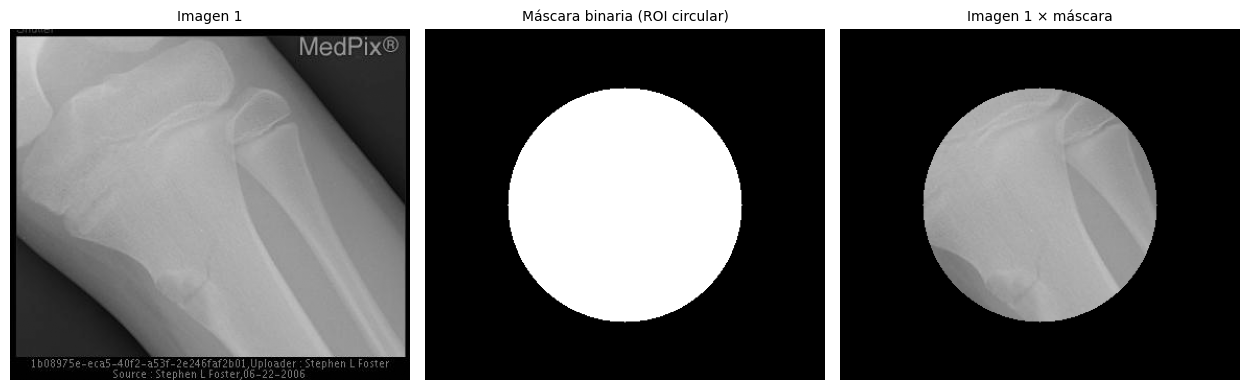

In [ ]:
# Aplicación práctica: multiplicar una imagen por una MÁSCARA binaria (ROI)
mascara = np.zeros_like(img1, dtype=np.uint8)
alto, ancho = img1.shape
cv2.circle(mascara, (ancho // 2, alto // 2), min(alto, ancho) // 3, 1, thickness=-1)   # 1 dentro de la ROI, 0 fuera

roi = img1 * mascara     # producto elemento por elemento: conserva solo la ROI

mostrar([img1, mascara * 255, roi],
        ["Imagen 1", "Máscara binaria (ROI circular)", "Imagen 1 × máscara"], cols=3)

# Parte II.- Operaciones lógicas

## Ejercicio 1: Ecualización

1. Se carga una radiografía de tórax de bajo contraste y se imprimen sus estadísticas.
2. Se obtiene y visualiza el histograma con `cv2.calcHist`.
3. Se aplica la ecualización con `cv2.equalizeHist`.
4. Se muestran la imagen original, la mejorada y la comparación de sus histogramas (con la CDF en rojo), junto con una tabla de estadísticas antes y después.

In [ ]:
# 1) Cargar imagen médica de bajo contraste
torax = cv2.imread("imagenes/torax_bajo_contraste.jpg", cv2.IMREAD_GRAYSCALE)
print("Tamaño:", torax.shape, "| tipo:", torax.dtype)
print(f"Rango de grises: [{torax.min()}, {torax.max()}]")
p5, p95 = np.percentile(torax, [5, 95])
print(f"Percentiles 5-95: [{p5:.0f}, {p95:.0f}]  ->  el 90 % de los píxeles está en solo {p95-p5:.0f} niveles de 256")
print(f"Desviación estándar (medida de contraste global): {torax.std():.1f}")

Tamaño: (440, 440) | tipo: uint8
Rango de grises: [54, 255]
Percentiles 5-95: [138, 225]  ->  el 90 % de los píxeles está en solo 87 niveles de 256
Desviación estándar (medida de contraste global): 31.4


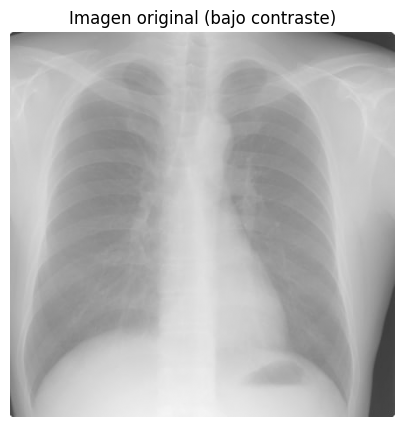

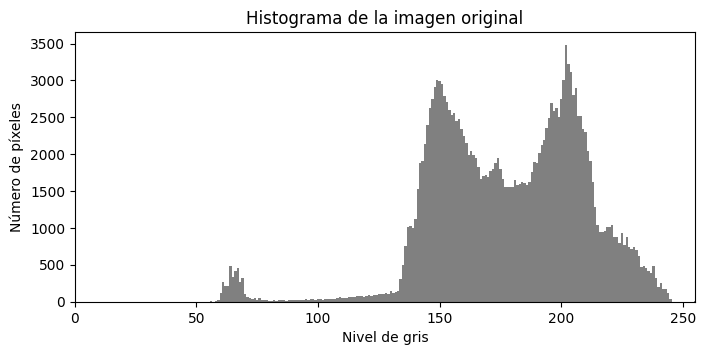

In [ ]:
# 2) Histograma de la imagen original
hist_orig = cv2.calcHist([torax], [0], None, [256], [0, 256]).ravel()

plt.figure(figsize=(5, 5))
plt.imshow(torax, cmap="gray", vmin=0, vmax=255)
plt.title("Imagen original (bajo contraste)")
plt.axis("off")
plt.show()

plt.figure(figsize=(8, 3.5))
plt.bar(np.arange(256), hist_orig, width=1.0, color="gray")
plt.title("Histograma de la imagen original")
plt.xlabel("Nivel de gris"); plt.ylabel("Número de píxeles")
plt.xlim(0, 255)
plt.show()

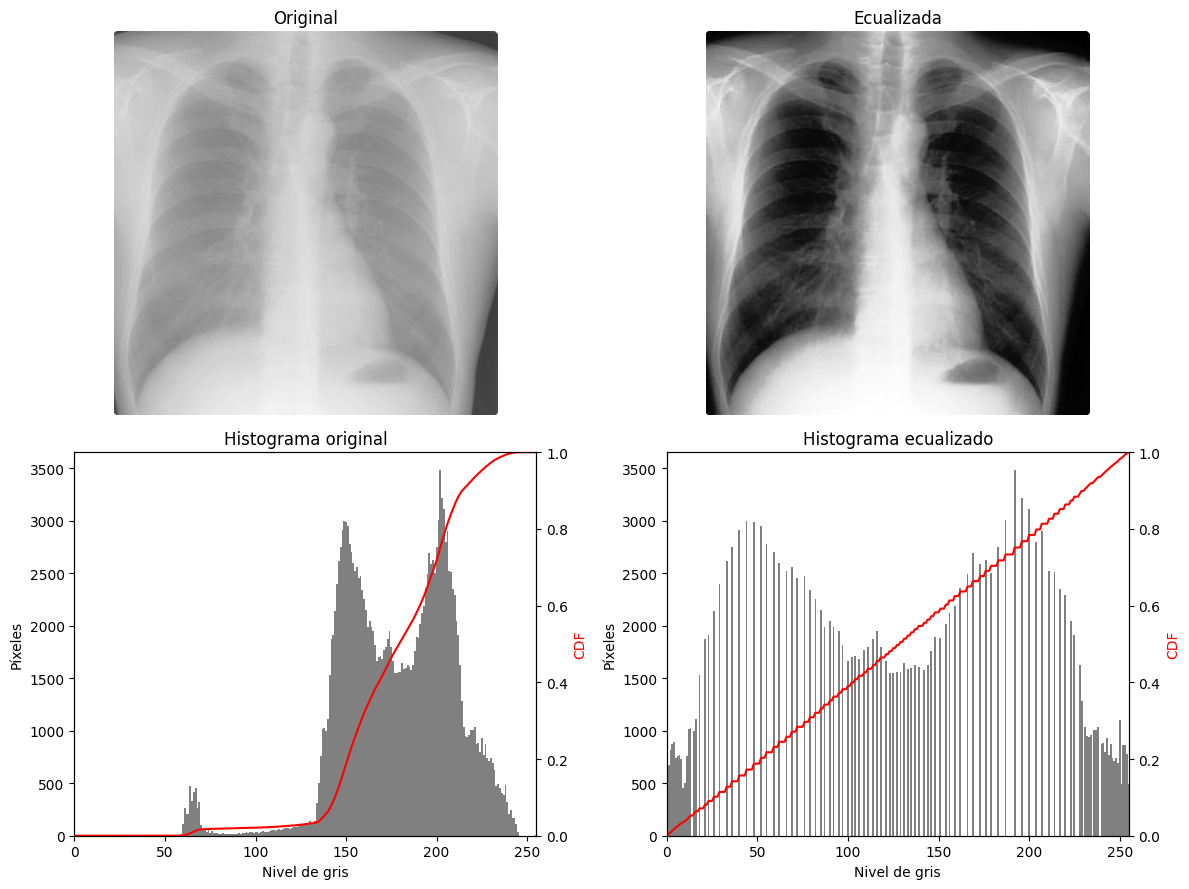

                        Original  Ecualizada
Mínimo                        54           0
Máximo                       255         255
Media                      178.2       128.8
Desviación estándar         31.4        73.6
Percentiles 5-95       [138,225]    [13,243]


In [ ]:
# 3) Ecualización de histograma
torax_eq = cv2.equalizeHist(torax)
hist_eq = cv2.calcHist([torax_eq], [0], None, [256], [0, 256]).ravel()

# CDF normalizadas (para comparar la función de transferencia)
cdf_orig = hist_orig.cumsum() / hist_orig.sum()
cdf_eq = hist_eq.cumsum() / hist_eq.sum()

# 4) Imagen original, imagen mejorada e histogramas
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
axs[0, 0].imshow(torax, cmap="gray", vmin=0, vmax=255); axs[0, 0].set_title("Original"); axs[0, 0].axis("off")
axs[0, 1].imshow(torax_eq, cmap="gray", vmin=0, vmax=255); axs[0, 1].set_title("Ecualizada"); axs[0, 1].axis("off")

axs[1, 0].bar(np.arange(256), hist_orig, width=1.0, color="gray")
axs[1, 0].set_title("Histograma original"); axs[1, 0].set_xlim(0, 255)
axs[1, 0].set_xlabel("Nivel de gris"); axs[1, 0].set_ylabel("Píxeles")
ax2 = axs[1, 0].twinx(); ax2.plot(cdf_orig, color="red"); ax2.set_ylabel("CDF", color="red"); ax2.set_ylim(0, 1)

axs[1, 1].bar(np.arange(256), hist_eq, width=1.0, color="gray")
axs[1, 1].set_title("Histograma ecualizado"); axs[1, 1].set_xlim(0, 255)
axs[1, 1].set_xlabel("Nivel de gris"); axs[1, 1].set_ylabel("Píxeles")
ax3 = axs[1, 1].twinx(); ax3.plot(cdf_eq, color="red"); ax3.set_ylabel("CDF", color="red"); ax3.set_ylim(0, 1)

plt.tight_layout()
plt.show()

print(f"{'':22s}{'Original':>10s}{'Ecualizada':>12s}")
print(f"{'Mínimo':22s}{torax.min():>10d}{torax_eq.min():>12d}")
print(f"{'Máximo':22s}{torax.max():>10d}{torax_eq.max():>12d}")
print(f"{'Media':22s}{torax.mean():>10.1f}{torax_eq.mean():>12.1f}")
print(f"{'Desviación estándar':22s}{torax.std():>10.1f}{torax_eq.std():>12.1f}")
p5e, p95e = np.percentile(torax_eq, [5, 95])
print(f"{'Percentiles 5-95':22s}{f'[{p5:.0f},{p95:.0f}]':>10s}{f'[{p5e:.0f},{p95e:.0f}]':>12s}")

## Complemento: operaciones lógicas

Se aplican `cv2.bitwise_not`, `cv2.bitwise_and`, `cv2.bitwise_or` y `cv2.bitwise_xor` sobre máscaras binarias. La primera máscara se obtiene umbralizando con Otsu la imagen ecualizada y la segunda es una región de interés rectangular.

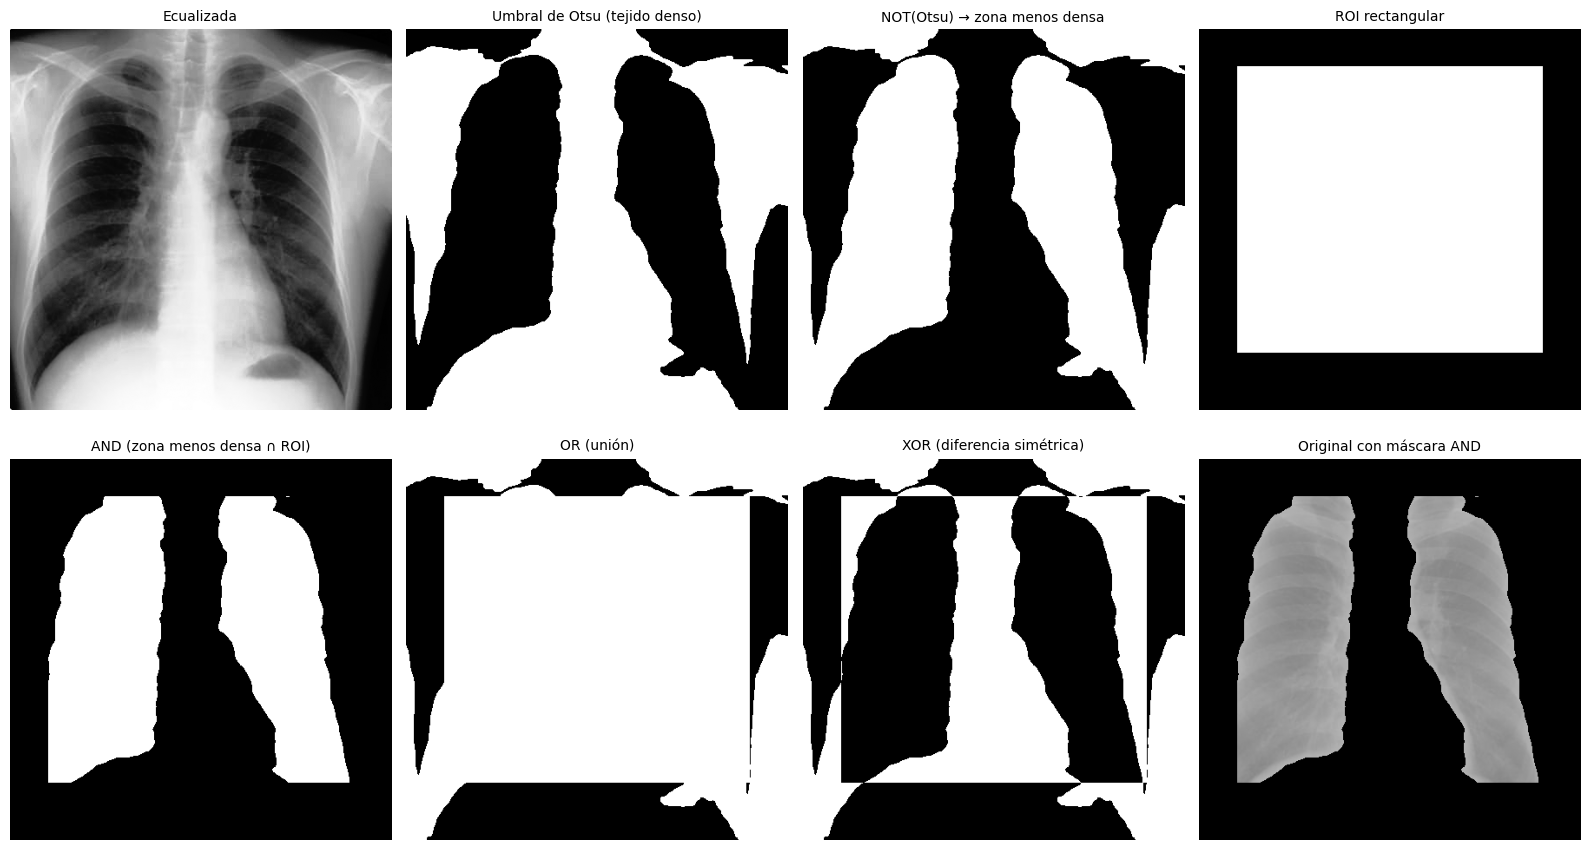

In [ ]:
# Segmentación sencilla por umbral de Otsu sobre la imagen ecualizada
suav = cv2.GaussianBlur(torax_eq, (7, 7), 0)
_, m_otsu = cv2.threshold(suav, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)   # tejidos densos (blanco)
m_pulmon = cv2.bitwise_not(m_otsu)                      # NOT: zonas menos densas (pulmón + aire)

# Segunda máscara: región de interés rectangular (parte central del tórax)
alto, ancho = torax.shape
roi = np.zeros_like(torax)
roi[int(0.10 * alto):int(0.85 * alto), int(0.10 * ancho):int(0.90 * ancho)] = 255

and_ = cv2.bitwise_and(m_pulmon, roi)    # pulmón DENTRO de la ROI
or_  = cv2.bitwise_or(m_pulmon, roi)     # unión
xor_ = cv2.bitwise_xor(m_pulmon, roi)    # solo en una de las dos
aplicada = cv2.bitwise_and(torax, torax, mask=and_)   # imagen original enmascarada

mostrar(
    [torax_eq, m_otsu, m_pulmon, roi, and_, or_, xor_, aplicada],
    ["Ecualizada", "Umbral de Otsu (tejido denso)", "NOT(Otsu) → zona menos densa", "ROI rectangular",
     "AND (zona menos densa ∩ ROI)", "OR (unión)", "XOR (diferencia simétrica)", "Original con máscara AND"],
    cols=4, figsize=(16, 9),
)